In [ ]:
import os
import glob
import sqlite3
import pandas as pd
import lightgbm as lgb
import numpy as np
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)

import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

DB_PATH = "olist.db"
DATA_DIR = "data"

1

In [ ]:

conn = sqlite3.connect(DB_PATH)
csv_files = glob.glob(os.path.join(DATA_DIR, "*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in '{DATA_DIR}'. Check folder path.")

print(f"Ingesting {len(csv_files)} CSV files into SQLite database '{DB_PATH}'...")

for file_path in csv_files:
    table_name = os.path.splitext(os.path.basename(file_path))[0]
    print(f" - Loading table: {table_name}")
    df = pd.read_csv(file_path)
    df.to_sql(table_name, conn, if_exists="replace", index=False)

print("\nIngestion complete. Verifying record counts:")
cursor = conn.cursor()
sample_tables = [
    "olist_orders_dataset",
    "olist_order_items_dataset",
    "olist_customers_dataset",
    "olist_order_reviews_dataset"
]

for table in sample_tables:
    cursor.execute(f"SELECT COUNT(*) FROM {table}")
    count = cursor.fetchone()[0]
    print(f"  • {table}: {count:,} rows")

conn.close()

Ingesting 10 CSV files into SQLite database 'olist.db'...
 - Loading table: olist_customers_dataset
 - Loading table: olist_geolocation_dataset
 - Loading table: olist_orders_dataset
 - Loading table: olist_order_items_dataset
 - Loading table: olist_order_payments_dataset
 - Loading table: olist_order_reviews_dataset
 - Loading table: olist_products_dataset
 - Loading table: olist_sellers_dataset
 - Loading table: product_category_name_translation
 - Loading table: training_features

Ingestion complete. Verifying record counts:
  • olist_orders_dataset: 99,441 rows
  • olist_order_items_dataset: 112,650 rows
  • olist_customers_dataset: 99,441 rows
  • olist_order_reviews_dataset: 99,224 rows


2

In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("olist.db")

audit_query = """
WITH UniqueOrderReviews AS (
    SELECT 
        order_id,
        AVG(review_score) AS avg_order_review_score,
        -- Check if any review was a 1-star
        MAX(CASE WHEN review_score = 1 THEN 1 ELSE 0 END) AS has_one_star
    FROM olist_order_reviews_dataset
    GROUP BY order_id
),
DeliveryData AS (
    SELECT 
        o.order_id,
        r.avg_order_review_score,
        r.has_one_star,
        CASE 
            WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 
            ELSE 0 
        END AS is_late
    FROM olist_orders_dataset o
    LEFT JOIN UniqueOrderReviews r 
        ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT 
    CASE WHEN is_late = 1 THEN 'Late' ELSE 'On Time' END AS delivery_status,
    COUNT(order_id) AS total_orders,
    ROUND(COUNT(order_id) * 100.0 / (SELECT COUNT(*) FROM DeliveryData), 2) AS share_pct,
    ROUND(AVG(avg_order_review_score), 2) AS avg_review_score,
    ROUND(SUM(has_one_star) * 100.0 / COUNT(order_id), 2) AS pct_orders_with_1_star
FROM DeliveryData
GROUP BY is_late;
"""

df_audit = pd.read_sql(audit_query, conn)
print("\n=== BASELINE BUSINESS AUDIT (Deduplicated Orders) ===")
print(df_audit.to_string(index=False))

geo_query = """
WITH UniqueOrderReviews AS (
    SELECT 
        order_id,
        AVG(review_score) AS avg_order_review_score
    FROM olist_order_reviews_dataset
    GROUP BY order_id
)
SELECT 
    c.customer_state,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 ELSE 0 END) * 100.0 / COUNT(DISTINCT o.order_id), 2) AS delay_rate_pct,
    ROUND(AVG(r.avg_order_review_score), 2) AS avg_score
FROM olist_orders_dataset o
JOIN olist_customers_dataset c ON o.customer_id = c.customer_id
LEFT JOIN UniqueOrderReviews r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY c.customer_state
HAVING total_orders > 500
ORDER BY delay_rate_pct DESC
LIMIT 5;
"""

df_geo = pd.read_sql(geo_query, conn)
print("\n=== TOP 5 HIGHEST RISK DESTINATIONS ===")
print(df_geo.to_string(index=False))

conn.close()


=== BASELINE BUSINESS AUDIT ===
delivery_status  total_orders  share_pct  avg_review_score  pct_1_star_reviews
        On Time         88644      91.89              4.29                6.56
           Late          7826       8.11              2.57               45.19

=== TOP 5 HIGHEST RISK DESTINATIONS ===
customer_state  total_orders  delay_rate_pct  avg_score
            MA           717           19.67       3.84
            CE          1279           15.40       3.94
            BA          3256           14.16       3.93
            RJ         12350           13.55       3.96
            PA           946           12.37       3.91


3

In [13]:
conn = sqlite3.connect(DB_PATH)

feature_query = """
WITH OrderItemsAgg AS (
    SELECT 
        oi.order_id,
        COUNT(oi.order_item_id) AS total_items,
        COUNT(DISTINCT oi.seller_id) AS total_sellers,
        SUM(oi.price) AS total_order_value,
        SUM(oi.freight_value) AS total_freight,
        ROUND(SUM(oi.freight_value) * 1.0 / NULLIF(SUM(oi.price), 0), 4) AS freight_to_price_ratio,
        AVG(p.product_weight_g) AS avg_product_weight_g,
        AVG(p.product_length_cm * p.product_height_cm * p.product_width_cm) AS avg_product_volume_cm3,
        -- Fetch primary seller location (most items in multi-item order)
        s.seller_state
    FROM olist_order_items_dataset oi
    JOIN olist_products_dataset p 
        ON oi.product_id = p.product_id
    JOIN olist_sellers_dataset s 
        ON oi.seller_id = s.seller_id
    GROUP BY oi.order_id
),
BaseOrders AS (
    SELECT 
        o.order_id,
        c.customer_state,
        o.order_purchase_timestamp,
        o.order_estimated_delivery_date,
        -- Calculated estimated transit days promised by platform
        ROUND(JULIANDAY(o.order_estimated_delivery_date) - JULIANDAY(o.order_purchase_timestamp), 1) AS estimated_delivery_days,
        -- Target variable (Late = 1, On Time = 0)
        CASE 
            WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 
            ELSE 0 
        END AS is_late
    FROM olist_orders_dataset o
    JOIN olist_customers_dataset c 
        ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT 
    b.order_id,
    b.customer_state,
    i.seller_state,
    CASE 
        WHEN b.customer_state = i.seller_state THEN 0 
        ELSE 1 
    END AS is_interstate,
    b.estimated_delivery_days,
    i.total_items,
    i.total_sellers,
    ROUND(i.total_order_value, 2) AS total_order_value,
    ROUND(i.total_freight, 2) AS total_freight,
    ROUND(i.freight_to_price_ratio, 4) AS freight_to_price_ratio,
    ROUND(i.avg_product_weight_g, 1) AS avg_product_weight_g,
    ROUND(i.avg_product_volume_cm3, 1) AS avg_product_volume_cm3,
    -- Extract order timing signals
    CAST(STRFTIME('%m', b.order_purchase_timestamp) AS INTEGER) AS purchase_month,
    CAST(STRFTIME('%w', b.order_purchase_timestamp) AS INTEGER) AS purchase_dayofweek,
    CAST(STRFTIME('%H', b.order_purchase_timestamp) AS INTEGER) AS purchase_hour,
    b.is_late
FROM BaseOrders b
JOIN OrderItemsAgg i 
    ON b.order_id = i.order_id
WHERE i.avg_product_weight_g IS NOT NULL
  AND i.avg_product_volume_cm3 IS NOT NULL;
"""

print("Executing SQL feature pipeline...")
df_features = pd.read_sql(feature_query, conn)

# Write view back to database for persistent caching
df_features.to_sql("ml_orders_features", conn, if_exists="replace", index=False)
conn.close()

# Save a CSV backup for fast iteration
df_features.to_csv("data/training_features.csv", index=False)

print(f"\nFeature pipeline complete!")
print(f"Dataset Shape: {df_features.shape[0]:,} rows, {df_features.shape[1]} columns")
print(f"Late orders count (target = 1): {df_features['is_late'].sum():,} ({df_features['is_late'].mean():.2%})")
print("\nSample records:")
print(df_features.head(3).T)

Executing SQL feature pipeline...

Feature pipeline complete!
Dataset Shape: 96,454 rows, 16 columns
Late orders count (target = 1): 7,826 (8.11%)

Sample records:
                                                        0  \
order_id                 e481f51cbdc54678b7cc49136f2d6af7   
customer_state                                         SP   
seller_state                                           SP   
is_interstate                                           0   
estimated_delivery_days                              15.5   
total_items                                             1   
total_sellers                                           1   
total_order_value                                   29.99   
total_freight                                        8.72   
freight_to_price_ratio                             0.2908   
avg_product_weight_g                                500.0   
avg_product_volume_cm3                             1976.0   
purchase_month                             

4

In [14]:
# 1. Load engineered features
print("Loading feature dataset...")
df = pd.read_csv("data/training_features.csv")

# 2. Define Features & Target
target = "is_late"
drop_cols = ["order_id", target]

X = df.drop(columns=drop_cols)
y = df[target]

# 3. Categorical encoding for LightGBM
cat_cols = ["customer_state", "seller_state"]
for col in cat_cols:
    X[col] = X[col].astype("category")

# 4. Train/Test Split (Stratified to maintain class imbalance ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train samples: {len(X_train):,} | Test samples: {len(X_test):,}")
print(f"Late orders in test set: {y_test.sum():,} ({y_test.mean():.2%})\n")

# 5. Handle Class Imbalance using scale_pos_weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count

print(f"Calculated negative-to-positive class weight: {scale_weight:.2f}")

# 6. Initialize & Train LightGBM
model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=scale_weight,
    random_state=42,
    importance_type="gain",
    verbose=-1
)

print("Training LightGBM model...")
model.fit(
    X_train, 
    y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
)

# 7. Predictions & Probability Scoring
y_probs = model.predict_proba(X_test)[:, 1]

# 8. Evaluation Metrics
roc_auc = roc_auc_score(y_test, y_probs)
pr_auc = average_precision_score(y_test, y_probs)

print("\n=== MODEL PERFORMANCE METRICS ===")
print(f"ROC-AUC Score:      {roc_auc:.4f}")
print(f"PR-AUC (Avg Prec):  {pr_auc:.4f} (Baseline naive rate: {y_test.mean():.4f})")

# 9. BA Operational Metric: Top Decile Capture Rate
test_results = pd.DataFrame({
    "actual": y_test.values,
    "prob": y_probs
}).sort_values(by="prob", ascending=False)

top_10_pct_cutoff = int(len(test_results) * 0.10)
top_10_pct = test_results.iloc[:top_10_pct_cutoff]
captured_late_orders = top_10_pct['actual'].sum()
total_late_orders = test_results['actual'].sum()
capture_rate = captured_late_orders / total_late_orders

print("\n=== BUSINESS VALUE METRICS ===")
print(f"Top 10% Highest-Risk Flagged Orders: {top_10_pct_cutoff:,}")
print(f"Actual Late Orders in Top 10%:       {captured_late_orders:,} out of {total_late_orders:,}")
print(f"Top Decile Capture Rate:             {capture_rate:.2%}")
print(f"Delay Rate inside Top 10% Flagged:   {top_10_pct['actual'].mean():.2%}")

Loading feature dataset...
Train samples: 77,163 | Test samples: 19,291
Late orders in test set: 1,565 (8.11%)

Calculated negative-to-positive class weight: 11.32
Training LightGBM model...

=== MODEL PERFORMANCE METRICS ===
ROC-AUC Score:      0.7563
PR-AUC (Avg Prec):  0.2273 (Baseline naive rate: 0.0811)

=== BUSINESS VALUE METRICS ===
Top 10% Highest-Risk Flagged Orders: 1,929
Actual Late Orders in Top 10%:       542 out of 1,565
Top Decile Capture Rate:             34.63%
Delay Rate inside Top 10% Flagged:   28.10%


c:\Users\acjdu\miniconda3\envs\myenv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


5

Computing SHAP values on test sample...


c:\Users\acjdu\miniconda3\envs\myenv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Saved plot to 'data/shap_summary_plot.png'

=== RANKED DELAY DRIVERS (SHAP IMPORTANCE) ===
                Feature  Mean_Absolute_SHAP
estimated_delivery_days            0.571132
         purchase_month            0.544068
         customer_state            0.419005
           seller_state            0.145301
          total_freight            0.144498
          is_interstate            0.120123
            total_items            0.109123
 avg_product_volume_cm3            0.078398
      total_order_value            0.057786
   avg_product_weight_g            0.056710
     purchase_dayofweek            0.052448
          total_sellers            0.042857
 freight_to_price_ratio            0.039467
          purchase_hour            0.027499


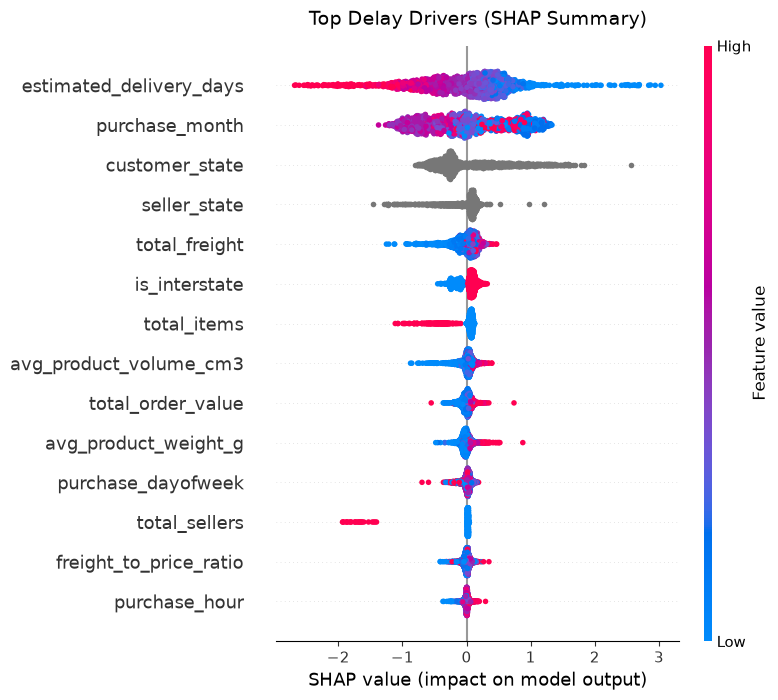

In [15]:
# 1. Load data
df = pd.read_csv("data/training_features.csv")
target = "is_late"
X = df.drop(columns=["order_id", target])
y = df[target]

# Encode categoricals
cat_cols = ["customer_state", "seller_state"]
for col in cat_cols:
    X[col] = X[col].astype("category")

# Stratified split matching Phase 4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Retrain model instance for SHAP explainer
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()

model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=(neg_count / pos_count),
    random_state=42,
    importance_type="gain",
    verbose=-1
)
model.fit(X_train, y_train)

# 3. TreeExplainer calculation
print("Computing SHAP values on test sample...")
# Subsample 2,000 records for fast calculation
sample_X_test = X_test.sample(2000, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(sample_X_test)

# If binary classification returns list [shap_class_0, shap_class_1], use index 1
if isinstance(shap_values, list):
    shap_vals_late = shap_values[1]
else:
    shap_vals_late = shap_values

# 4. Generate & Save SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_late, sample_X_test, show=False)
plt.title("Top Delay Drivers (SHAP Summary)", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig("data/shap_summary_plot.png", dpi=300)
print("Saved plot to 'data/shap_summary_plot.png'")

# 5. Extract Feature Impact Rankings
mean_abs_shap = np.abs(shap_vals_late).mean(axis=0)
shap_rankings = pd.DataFrame({
    "Feature": sample_X_test.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values(by="Mean_Absolute_SHAP", ascending=False)

print("\n=== RANKED DELAY DRIVERS (SHAP IMPORTANCE) ===")
print(shap_rankings.to_string(index=False))